In [10]:
#kernel used is cannon2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from astropy.stats import sigma_clip

In [11]:
from astropy.io import ascii as asc
# or
from astropy.table import Table

In [12]:
J0056 = Table.read("/Users/leighharwell2/Desktop/DW/IRchara/lightcurve/J0056-0611.tbl",format="ascii")
#loads in the tables with proper formatting and heading labels
#astropy is able to read in more astro based tables and their formating better that other tools like pandas or numpy

In [13]:
#plotting the light curve of the system and constraining it so that we can see the secondary better without too much noise
#need the flux from the systems and observation frame of the light curve
wl56 = J0056['lambda']
flux56 = J0056['flux']
flux_err56 = J0056['flux_err']

In [14]:
#creating a light curve plot
wl56 = np.array(wl56, dtype = float) #μm
f56 = np.array(flux56, dtype = float) #e.g. μJy
err56 = np.array(flux_err56, dtype = float) 
t56 = np.array(J0056['mjd'], dtype = float) #modified julian date

In [15]:
# 1. Error / S/N cut, plus basic sanity checks
good = (np.isfinite(t56) & np.isfinite(wl56) & np.isfinite(f56) & np.isfinite(err56)
        & (err56 > 0)
        & (err56 < np.nanpercentile(err56, 90))   # drop the noisiest 10% (or use a fixed value, e.g. err_all < 50)
        & (wl56 > 0.7) & (wl56 < 5.0))            # SPHEREx range, adjust as needed


In [16]:
t56, wl56, f56, f_err56 = t56[good], wl56[good], f56[good], err56[good]

Part 1: Quality mask

np.isfinite(...) is false for NaN and +- inf. NaNs would break the percentile calculations and the plotting, so they go first
err56 > 0 removes zero and negative uncertainties, which are unphysical and usually flag bad pixels or failed fits
err56 < np.nanpercentile(err56, 90) computes the 90th-percentile error value (nanppercentile ingores NaNs) and keeps only points whose error is below it. This drops the noisiest 10% of measurements, whose huge error bars were streching the plots. Errors often depend on wavelengths, so this cut can rmove some wl regions more than others. a fixed threshold is easier to defend in a paper.
(wl56 > 0.7) & (wl < 5) restricts to the instruments wl range.

In [17]:
# 2. Outlier clipping relative to the local trend (per wavelength bin)
bins = np.linspace(wl56.min(), wl56.max(), 25)
idx = np.digitize(wl56, bins)
keep = np.ones(len(f56), dtype=bool)
for i in np.unique(idx):
    m = idx == i
    if m.sum() > 3:
        clipped = sigma_clip(f56[m], sigma=3, maxiters=5)
        keep[np.where(m)[0]] = ~clipped.mask

t56, wl56, f56, f_err56 = t56[keep], wl56[keep], f56[keep], f_err56[keep]

part 2: Per-bin sigma clipping

Binning:
linspace creates 25 evenly spaced edged, which make 24 wl bins. np.digitize returns for each point which bin it falls in (1 for the first bin, and so on). The result idx is an integer array the same length as wl56

The Loop:

keep starts as all True, meaning keep everything unless proven an outlier
for each occupied bin, m is a mask selecting the points in the bin.
if m.cum() > 3 skips bins with too few points, since statistics on 2 or 3 points are meaningless. those points are kept by default
sigma_clip from astropy works iteratively: it computes the median and standard deviation of the bins fluxes, flags anything more than 3 standard deviations from the median, recomputes without the flagged points, and repeats until nothing new is flagged or it hits 5 itrations. Repeating matters because one huge outlier inflates the standard deviation and can hide itself and smaller outliers on the first pass.
it returns a masked array where .mask is True for clipped points. ~ flips that, so True means keep.
np.where(m)[0] gives the global positions of the bin's points, so the result gets written back into the right slots of keep

Limitations: the clipping ignores your error bars and treats all points in a bin equally. It also compares points across all epochs within a bin, so if your source truly varies in time, real variability can be clipped. If variability is the science goal, use a looser sigma or clip against a time-aware trend instead.

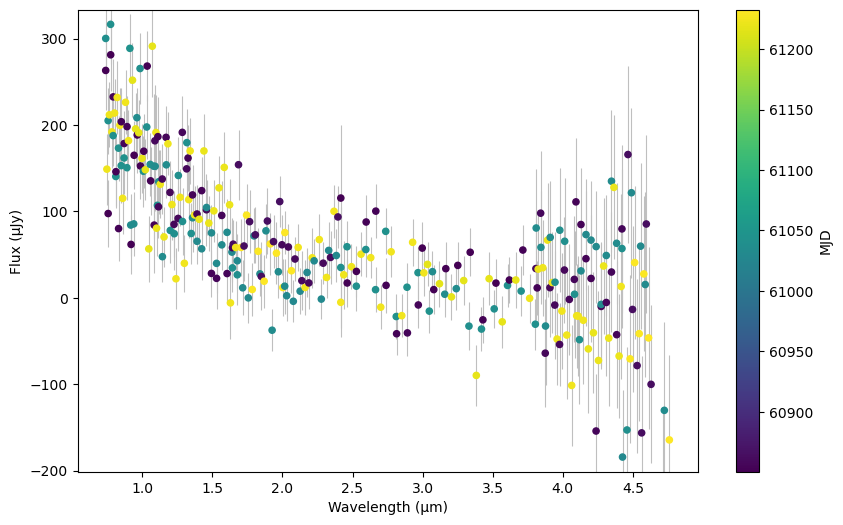

In [18]:
# 3. Plot, with y-limits set from percentiles so stragglers don't squash the curve
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(wl56, f56, yerr=f_err56, fmt='none', ecolor='0.75', elinewidth=0.8, capsize=0, zorder=1)
sc = ax.scatter(wl56, f56, c=t56, cmap='viridis',
                norm=Normalize(vmin=t56.min(), vmax=t56.max()), s=20, zorder=2)

lo, hi = np.percentile(f56, [1, 99])
pad = 0.1 * (hi - lo)
ax.set_ylim(lo - pad, hi + pad)

ax.set_xlabel('Wavelength (μm)')
ax.set_ylabel('Flux (μJy)')
fig.colorbar(sc, ax=ax).set_label('MJD')
plt.show()